In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import pandas as pd
import numpy as np
import json
import random
from xgboost import XGBRegressor, XGBClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV

from src.utils import df_features_to_numpy, df_target_to_numpy
from src.splitting import split_estratificado_autor
from src.metricas import tabla_metricas, evaluar_metricas_clasificacion, evaluar_metricas_regresion
from src.graficos import plot_confusion_matrix, plot_learning_curves_xgboost_regression, plot_learning_curves_xgboost_classification, plot_feature_importance_xgb, plot_learning_curves_randomforest_regression, plot_learning_curves_randomforest_classification, plot_feature_importance_rf

# Cargo el dataset ya procesado

In [3]:
#otra manera de leer el dataset, introduce aleatoriedad en las filas, no agarra las 100mil primeras
#tardo aprox 3min14s en correr
K = 100_000
sample = []

with open("goodreads_us_english_primer_filtrado.json", encoding="utf8") as f:
    for i, line in enumerate(f):
        obj = json.loads(line)

        if i < K:
            sample.append(obj)
        else:
            j = random.randint(0, i)
            if j < K:
                sample[j] = obj

df = pd.DataFrame(sample)
#REPETIR PARA EL TRAIN, VAL Y TEST
#TODO: comentario de clara para clara: descomentar este bloque antes de correr

In [4]:
#chunks33 = pd.read_json("goodreads_us_english_primer_filtrado.json", lines=True, chunksize=100_000)
#
#chunk_list33 = []
#for chunk in chunks33:
#    chunk_list33.append(chunk)
#
#df_us_en_1_filtro = pd.concat(chunk_list33, ignore_index = True)
#print(df_us_en_1_filtro.shape)
#TODO: comentario de clara para clara: comentar este bloque antes de correr

## Temporal, sacar cuando este el json ya procesado posta

In [5]:
#TEMPORAL: normalmente estas features ya van a estar agrupadas
from src.features import normalize_format
#Le aplico la funcion para reagrupar:
if "format_group" not in df.columns:
    df["format_group"] = df["format"].apply(normalize_format)

print(df["format_group"].value_counts())

format_group
PAPERBACK    54123
HARDCOVER    22129
EBOOK        17242
UNKNOWN       4253
AUDIO         1657
OTHER          550
COMIC           46
Name: count, dtype: int64


In [6]:
#TEMPORAL: normalmente los generos ya van a estar definidos
from src.features import extraer_generos_libro
df["genres"] = df["popular_shelves"].apply(extraer_generos_libro)

In [7]:
#TEMPORAL: ya va a estar hecho el one hot de estas features
from src.features import multi_binarizer_format, multi_binarizer_genre, one_hot_format
#df = multi_binarizer_format(df) #multi binarizer de format
df = one_hot_format(df)
df = multi_binarizer_genre(df) #multi binarizer de genero

In [8]:
def extraer_autor_principal(autores_sin_preprocesar):
    """
    autores_sin preprocesar: [{authorId, role}, {authorid, role})]
    Asumimos que el primer elemento de la lista es el autor principal (orden tipico de Goodreads)
    """
    # Buscar el primero con role vacío; si no hay, usar el primero de la lista
    for dic_autores in autores_sin_preprocesar:
        if dic_autores["role"] == "":
            return dic_autores["author_id"]
    return autores_sin_preprocesar[0]["author_id"]

df["author_id_principal"] = df["authors"].apply(extraer_autor_principal)

In [9]:
df_train, df_val, df_test = split_estratificado_autor(df, test_size=0.15, val_size=0.15)

print(f"Train: {len(df_train)} ({len(df_train)/len(df):.1%})")
print(f"Val: {len(df_val)} ({len(df_val)/len(df):.1%})")
print(f"Test: {len(df_test)} ({len(df_test)/len(df):.1%})")

#Verificacion: distribución de estrellas en cada split
for nombre, d in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"\n{nombre}:")
    print(d["estrellas"].value_counts(normalize=True).sort_index())

Train: 72246 (72.2%)
Val: 12846 (12.8%)
Test: 14908 (14.9%)

train:
estrellas
0    0.002408
1    0.001398
2    0.009329
3    0.147468
4    0.774410
5    0.064986
Name: proportion, dtype: float64

val:
estrellas
0    0.002647
1    0.001401
2    0.009030
3    0.143624
4    0.778764
5    0.064534
Name: proportion, dtype: float64

test:
estrellas
0    0.002549
1    0.001409
2    0.009123
3    0.143748
4    0.780118
5    0.063053
Name: proportion, dtype: float64


# FIN DE TEMPORAL

## Preparacion de los datos

In [10]:
generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
features = ["is_series", "publication_year", "num_pages", 'format_group_AUDIO', 'format_group_COMIC', 'format_group_EBOOK', 'format_group_HARDCOVER', 'format_group_OTHER', 'format_group_PAPERBACK'] + generos #'format_group_UNKNOWN' la saco por el one hot en regresion

#Me quedo solo con las features necesarias para el modelo base y las estandarizo
dfs = [df_train, df_val, df_test]
y_train_regresion, y_val_regresion, y_test_regresion = df_target_to_numpy("average_rating", dfs)
y_train_clasificacion, y_val_clasificacion, y_test_clasificacion = df_target_to_numpy("estrellas", dfs)
X_train, X_val, X_test = df_features_to_numpy(features, dfs)

#estandarizo los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val) #escala X_val con los valores sacados de X_train
#TODO: escalar el X_test

## XGBoost con features basicas - Regresion

In [11]:
#subsample --> en cada arbol solo usa una fraccion de las filas (muestras) --> ayuda a descorrelacionar
#colsample_bytree --> solo usa una fraccion de las columnas (features) --> ayuda a descorrelacionar
modeloXGBoostRegresion = XGBRegressor(n_estimators = 50, max_depth = 4, learning_rate = 0.05, subsample = 0.8, colsample_bytree = 0.8, objective = "reg:squarederror", random_state = 42) #MInimiza MSE
modeloXGBoostRegresion.fit(X_train_scaled, y_train_regresion) #XGBoost no requiere obligatoriamnete que se escalen los valores, pero lo hag para poder comprar la feature importance

y_pred_train_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_train_scaled)
y_pred_val_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_val_scaled)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloXGBoostRegresion, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloXGBoostRegresion, y_val_regresion)
print(tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"]))

         Train  Validation
MSE   0.232546    0.234362
RMSE  0.482230    0.484110
MAE   0.330693    0.328856
R²    0.081519    0.068708


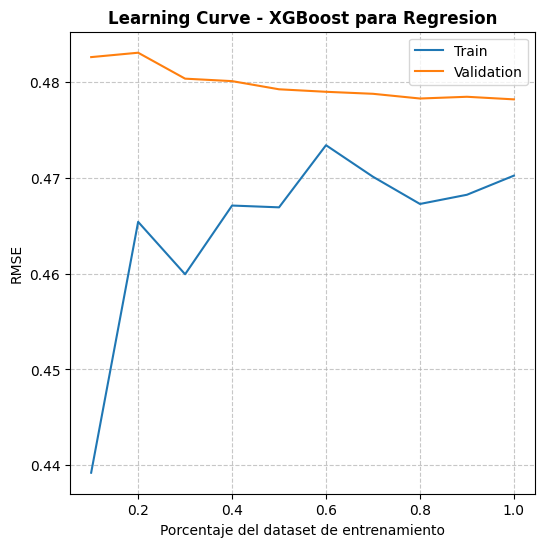

In [12]:
plot_learning_curves_xgboost_regression(X_train_scaled, y_train_regresion, X_val_scaled, y_val_regresion, n_estimators = 300, max_depth = 4, learning_rate = 0.05, subsample = 0.8, colsample_bytree = 0.8, objective = "reg:squarederror", random_state = 42)

Analizamos las feature importance:

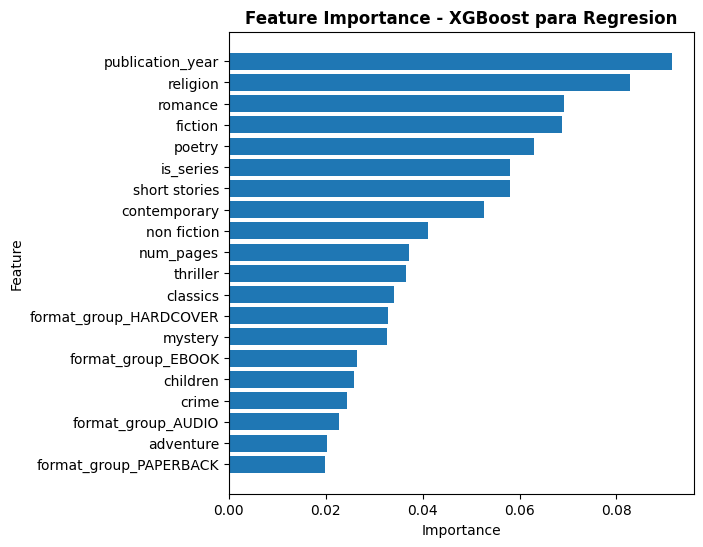

In [13]:
importancias_coef_xgb_reg = pd.DataFrame({"feature": features, "importance": modeloXGBoostRegresion.feature_importances_})
importancias_coef_xgb_reg = importancias_coef_xgb_reg.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_reg, "para Regresion")

## XGBoost con features basicas - Clasificacion

              Train  Validation
Accuracy   0.774410    0.778764
Precision  0.129068    0.129794
Recall     0.166667    0.166667
F1         0.145477    0.145937


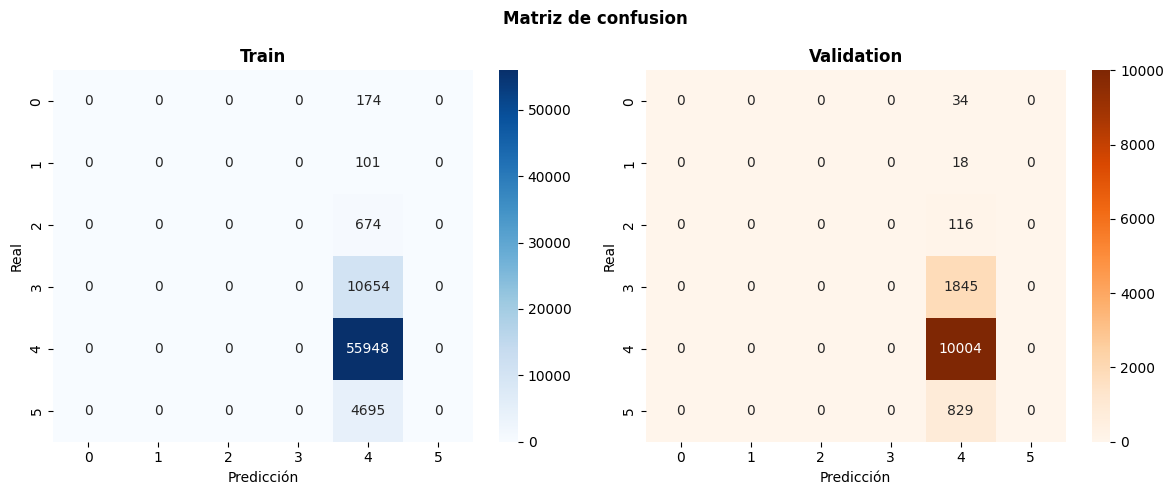

In [14]:
modeloXGBoostClasificacion = XGBClassifier(n_estimators = 50, max_depth = 4, learning_rate = 0.05, subsample = 0.8, colsample_bytree = 0.8, objective = "multi:softmax", num_class = 5, random_state = 42) 
modeloXGBoostClasificacion.fit(X_train_scaled, y_train_clasificacion) #XGBoost no requiere obligatoriamnete que se escalen los valores, pero lo hag para poder comprar la feature importance

y_pred_train_modeloXGBoostClasificacion = (modeloXGBoostClasificacion.predict(X_train_scaled))
y_pred_val_modeloXGBoostClasificacion = (modeloXGBoostClasificacion.predict(X_val_scaled))

metricas_train = evaluar_metricas_clasificacion(y_pred_train_modeloXGBoostClasificacion, y_train_clasificacion)
metricas_val = evaluar_metricas_clasificacion(y_pred_val_modeloXGBoostClasificacion, y_val_clasificacion)
tabla_metricas_xgboost_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_xgboost_clasificacion)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_modeloXGBoostClasificacion)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_modeloXGBoostClasificacion)
plot_confusion_matrix(cm_train, cm_val)

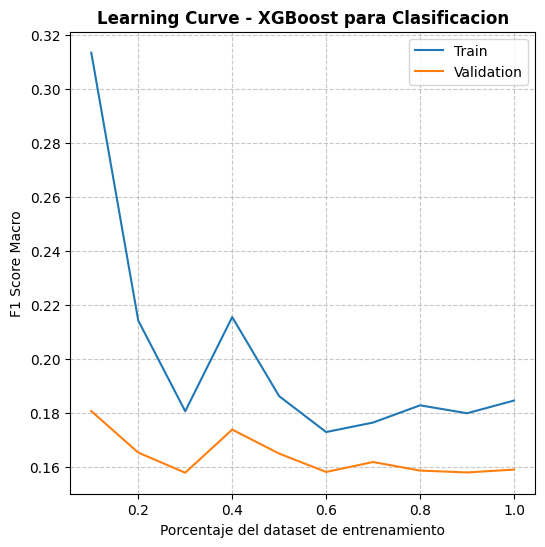

In [15]:
plot_learning_curves_xgboost_classification(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, n_estimators = 300, max_depth = 4, learning_rate = 0.05, subsample = 0.8, colsample_bytree = 0.8, objective = "multi:softmax", random_state = 42)

Analizamos las feature importance:

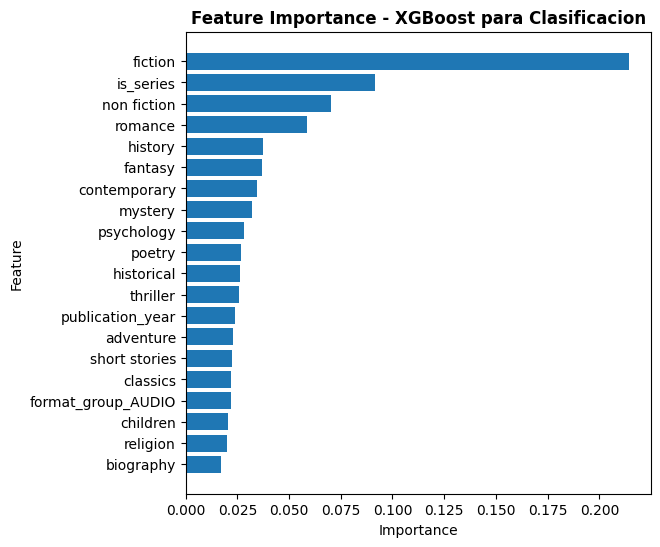

In [18]:
importancias_coef_xgb_clasf = pd.DataFrame({"feature": features, "importance": modeloXGBoostClasificacion.feature_importances_})
importancias_coef_xgb_clasf = importancias_coef_xgb_clasf.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_clasf, "para Clasificacion")

## Random Forest con features basicas - Regresion

Grid Search: tomo una muestra de 100 mil datos para encontrar los mejores hiperparametros, una vez encontrados estos valores reentreno con todos los datos

In [ ]:
idx = np.random.choice(len(X_train), size = 100_000, replace = False)
X_sub = X_train[idx]
y_sub = y_train_regresion[idx]

parametros_grid_search = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

RandomForestGridSearchRegresion = RandomForestRegressor(random_state=42)
grid = GridSearchCV(estimator = RandomForestGridSearchRegresion, param_grid = parametros_grid_search, cv = 3, scoring="r2", n_jobs=2, verbose=2)
grid.fit(X_sub, y_sub)

print(f"Mejores parametros: {grid.best_params_}")
print(f"Mejor R² CV: {grid.best_score_}")

In [ ]:
modeloRandomForestRegresion = grid.best_estimator_ #mejor modelo encontrado con grid search
y_pred_train_modeloRandomForestRegresion = modeloRandomForestRegresion.predict(X_train)
y_pred_val_modeloRandomForestRegresion = modeloRandomForestRegresion.predict(X_val)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloRandomForestRegresion, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloRandomForestRegresion, y_val_regresion)
print(tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"]))

         Train  Validation
MSE   0.213956    0.231814
RMSE  0.462554    0.481471
MAE   0.315766    0.324393
R²    0.154943    0.078834


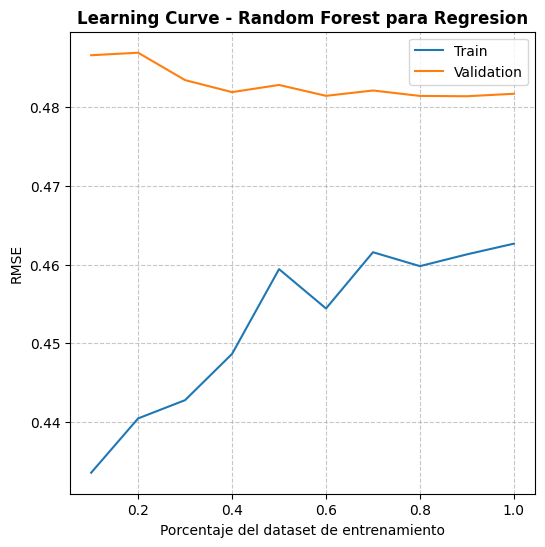

In [ ]:
plot_learning_curves_randomforest_regression(X_train, y_train_regresion, X_val, y_val_regresion, 100, 10)

Analizamos la feature importance:

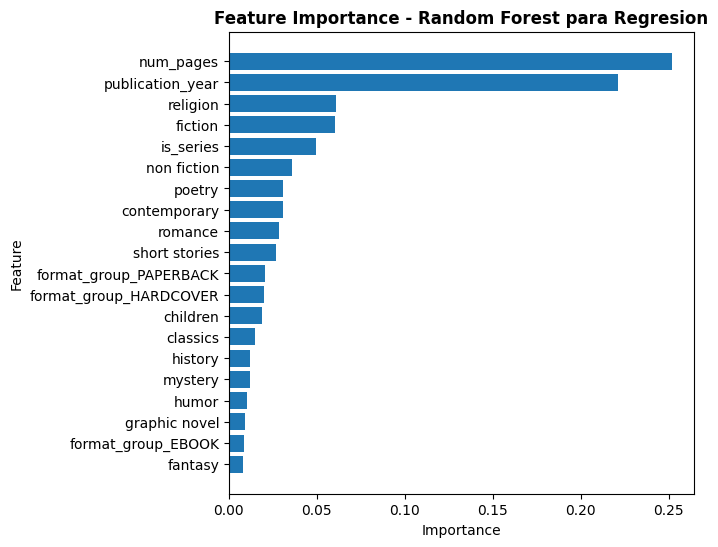

In [27]:
importancias_coef_rf_reg = pd.DataFrame({"feature": features, "importance": modeloRandomForestRegresion.feature_importances_})
importancias_coef_rf_reg = importancias_coef_rf_reg.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_reg, "para Regresion")

## Random Forest con features basicas - Clasificacion

In [ ]:
RandomForestGridSearchClasificacion = RandomForestClassifier(random_state = 42)

#uso las mismas opciones de hiperparametros q use en regresion
grid = GridSearchCV(estimator = RandomForestGridSearchClasificacion, param_grid = parametros_grid_search, cv = 3, scoring = "f1_macro", n_jobs = 2, verbose = 2)
grid.fit(X_train, y_train_clasificacion)

print(f"Mejores parametros: {grid.best_params_}")
print(f"Mejor F1 CV: {grid.best_score_}")

              Train  Validation
Accuracy   0.774548    0.778764
Precision  0.462419    0.129794
Recall     0.167002    0.166667
F1         0.146158    0.145937


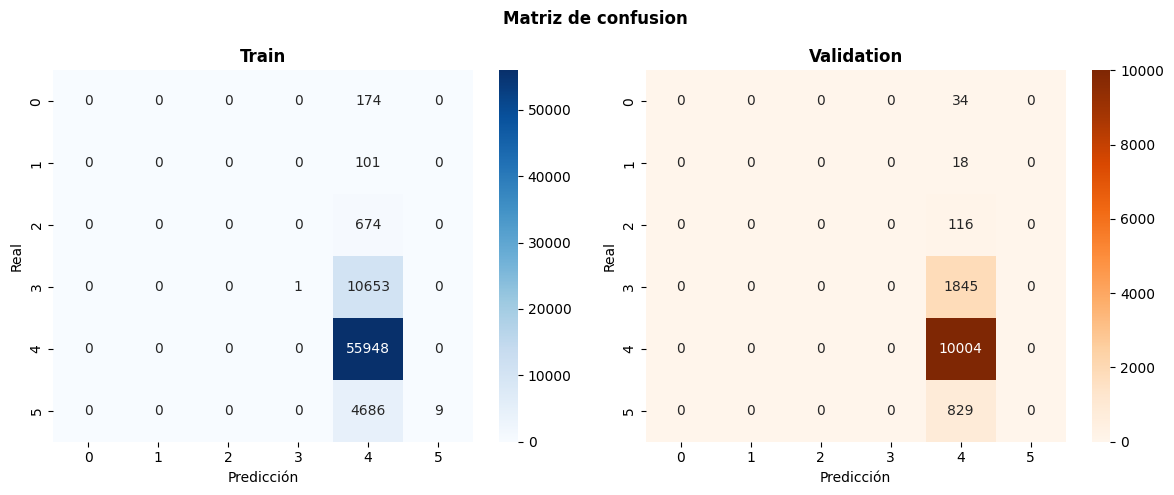

In [ ]:
modeloRandomForestClasificacion = grid.best_estimator_
y_pred_train_modeloRandomForestClasificacion = (modeloRandomForestClasificacion.predict(X_train))
y_pred_val_modeloRandomForestClasificacion = (modeloRandomForestClasificacion.predict(X_val))

metricas_train = evaluar_metricas_clasificacion(y_pred_train_modeloRandomForestClasificacion, y_train_clasificacion)
metricas_val = evaluar_metricas_clasificacion(y_pred_val_modeloRandomForestClasificacion, y_val_clasificacion)
tabla_metricas_rf_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_rf_clasificacion)

cm_train = confusion_matrix(y_train_clasificacion, y_pred_train_modeloRandomForestClasificacion)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_modeloRandomForestClasificacion)
plot_confusion_matrix(cm_train, cm_val)

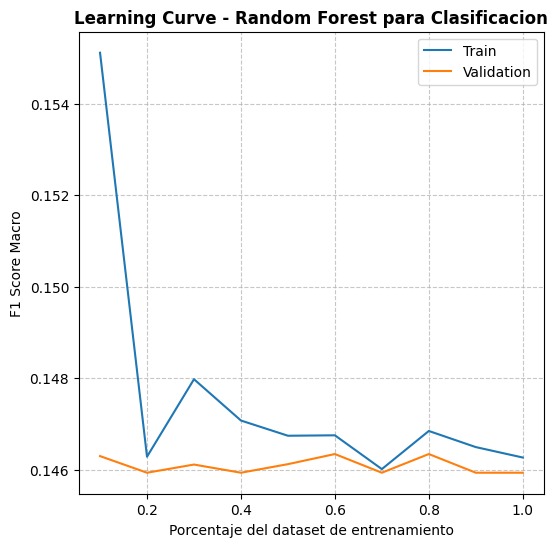

In [32]:
plot_learning_curves_randomforest_classification(X_train, y_train_clasificacion, X_val, y_val_clasificacion, 100, 10)

Analizamos la feature importance:

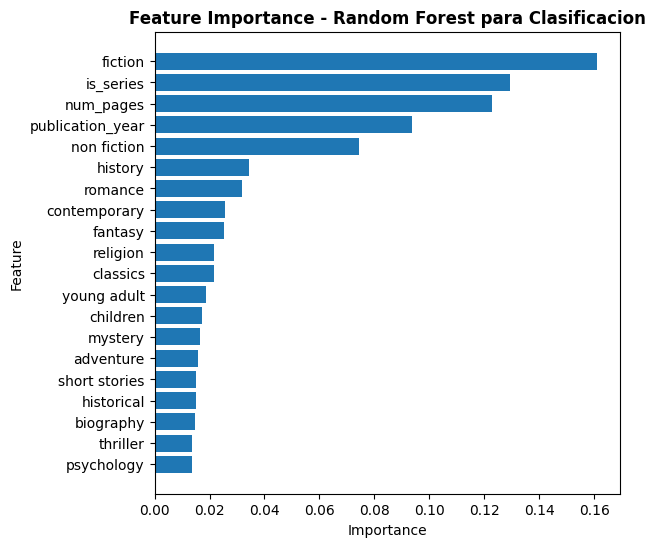

In [33]:
importancias_coef_rf_clasf = pd.DataFrame({"feature": features, "importance": modeloRandomForestClasificacion.feature_importances_})
importancias_coef_rf_clasf = importancias_coef_rf_clasf.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_clasf, "para Clasificacion")